# Sprint 3 — Alertas determinísticos e fiéis

## Objetivo
Transformar leituras do motor W22 em episódios e alertas rastreáveis. O texto é montado com fatos calculados; o LLM apenas reescreve o template e toda resposta passa pelo verificador F1.

| Entregável | Seção |
|---|---:|
| Dados, mapeamento canônico e aviso sobre `data_variables.json` | 2 |
| Distribuição por severidade e limiares | 3 |
| Episódios e exemplos reais rastreáveis | 4 |
| Templates por severidade | 5 |
| Redação verificada por LLM | 6 |
| ROUGE e checklist de qualidade | 7 |
| Exportação JSON | 8 |


## 1. Configuração do ambiente

Em Colab, clone o repositório somente quando `src/` ainda não estiver disponível, instale as dependências fixadas e carregue `OPENROUTER_API_KEY` dos Secrets. A célula mostra somente se a chave foi carregada.


In [1]:
from pathlib import Path
import os
import subprocess
import sys

REPOSITORY_URL = "https://github.com/entregas-faculdade/Sprint-4-NLP.git"
REPOSITORY_DIRECTORY = "Sprint-4-NLP"


def _is_repository_root(directory: Path) -> bool:
    return (
        (directory / "src" / "pln" / "config.py").is_file()
        and (directory / "requirements.txt").is_file()
    )


def _find_repository_root(start_directory: Path) -> Path | None:
    resolved_start = start_directory.resolve()
    candidates = (resolved_start, *resolved_start.parents)
    return next(
        (candidate for candidate in candidates if _is_repository_root(candidate)),
        None,
    )


repository_root = _find_repository_root(Path.cwd())
if repository_root is None:
    clone_directory = Path.cwd() / REPOSITORY_DIRECTORY
    repository_root = _find_repository_root(clone_directory)
    if repository_root is None:
        subprocess.run(["git", "clone", REPOSITORY_URL, str(clone_directory)], check=True)
        repository_root = _find_repository_root(clone_directory)
if repository_root is None:
    raise RuntimeError("N\u00e3o foi poss\u00edvel localizar a raiz do reposit\u00f3rio ap\u00f3s o clone.")
if _find_repository_root(repository_root / "notebooks") != repository_root:
    raise RuntimeError("A raiz do reposit\u00f3rio n\u00e3o foi reconhecida a partir de notebooks/.")

repository_root_string = str(repository_root)
sys.path[:] = [
    repository_root_string,
    *(entry for entry in sys.path if entry != repository_root_string),
]
os.chdir(repository_root)

%pip install -q -r requirements.txt

from src.pln.llm import load_openrouter_api_key

try:
    openrouter_key_available = bool(load_openrouter_api_key())
except RuntimeError:
    openrouter_key_available = False

print("chave carregada:", openrouter_key_available)


Note: you may need to restart the kernel to use updated packages.
chave carregada: True



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: C:\Users\Igor\AppData\Local\Programs\Python\Python311\python.exe -m pip install --upgrade pip


## 2. Dados e mapeamento canônico

O mapeamento abaixo combina as descrições e a magnitude observada. `data_variables.json` tem nomes e unidades inconsistentes com suas descrições e magnitudes; por isso, o catálogo registra a grandeza canônica e preserva a descrição original para auditoria.


In [2]:
import json
import pandas as pd

from src.pln.alertas import carregar_leituras
from src.pln.config import ALERT_TESTS_FILE
from src.pln.sensores import carregar_sensores

sensor_catalog = carregar_sensores()
readings = carregar_leituras()
alert_test_cases = json.loads(ALERT_TESTS_FILE.read_text(encoding="utf-8"))["casos"]
llm_test_results = []
real_redactions = {}

sensor_rows = [
    {
        "variable_id": sensor.variable_id,
        "grandeza": sensor.grandeza,
        "unidade": sensor.unidade,
        "limiares": sensor.limiares,
    }
    for sensor in sensor_catalog.values()
]
print(pd.DataFrame(sensor_rows).to_string(index=False))
print("Leituras carregadas:", len(readings))


                         variable_id                             grandeza unidade                                                   limiares
156b96a1-8899-463f-9311-c0cf754066ae                   Velocidade do eixo     rpm {'nominal': 1750.0, 'warning': 1800.0, 'critical': 1850.0}
3f809255-7687-4d25-92da-b8e134dcd01d     Vibração no mancal lado acoplado    mm/s          {'nominal': 1.5, 'warning': 2.8, 'critical': 4.5}
472e04da-4863-4f49-9cb8-1c9e164a4fa4                      Vibração global    mm/s                                                       None
8addd89b-70a5-4727-b2c0-bcea6b5c2d78           Corrente elétrica por fase       A    {'nominal': 125.0, 'warning': 140.0, 'critical': 160.0}
9c611f84-fb81-4db0-969e-7507d35e6761 Temperatura do enrolamento (estator)      °C      {'nominal': 75.0, 'warning': 90.0, 'critical': 110.0}
aa09b4cd-3b6b-4f56-8991-402ec305d26d      Temperatura interna das bobinas      °C                                                       None
Leituras carr

## 3. Severidade e limiares

A severidade é calculada por leitura. Valores abaixo do nominal são normais; nominal inicia a faixa leve, `warning` inicia a moderada e `critical` inicia a crítica. Sensores sem limiar ficam fora da contagem de alertas.


{'normal': 9918, 'leve': 12055, 'moderado': 3961, 'critico': 2818}


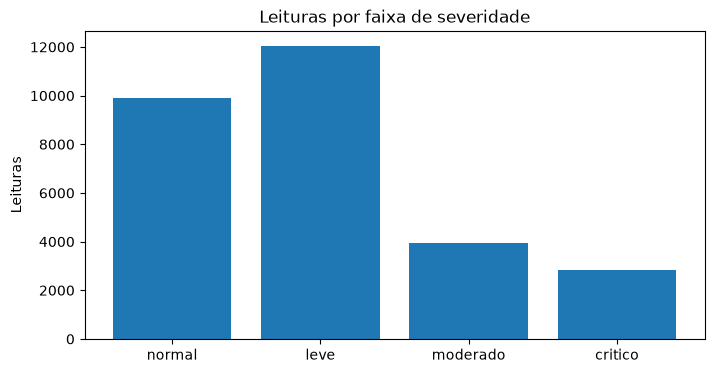

In [3]:
from collections import Counter
import matplotlib.pyplot as plt

from src.pln.alertas import classificar_severidade

severity_counts = Counter()
for reading in readings:
    sensor = sensor_catalog[reading["variable_id"]]
    if sensor.limiares is not None:
        severity = classificar_severidade(reading["value"], sensor.limiares)
        severity_counts[severity] += 1

severity_order = ["normal", "leve", "moderado", "critico"]
print({severity: severity_counts[severity] for severity in severity_order})
figure, axis = plt.subplots(figsize=(8, 4))
axis.bar(severity_order, [severity_counts[item] for item in severity_order])
axis.set_title("Leituras por faixa de severidade")
axis.set_ylabel("Leituras")
plt.show()


## 4. Episódios → alertas

Leituras consecutivas do mesmo sensor formam um episódio quando o intervalo é de até 60 minutos. O episódio recebe a maior severidade presente; episódios leves com menos de três leituras são descartados.


In [4]:
from collections import Counter

from src.pln.alertas import detectar_episodios, gerar_template

real_alerts = detectar_episodios(readings, sensor_catalog)
real_counts = Counter(alert.severidade for alert in real_alerts)
print({severity: real_counts[severity] for severity in ("leve", "moderado", "critico")})

real_examples = {}
for severity in ("leve", "moderado", "critico"):
    alert = next(item for item in real_alerts if item.severidade == severity)
    real_examples[severity] = alert
    print(f"\n{severity.upper()} | {alert.id} | leituras: {', '.join(alert.ids_leitura)}")
    print(gerar_template(alert))

synthetic_alerts = []
for case in alert_test_cases:
    alerts = detectar_episodios(case["leituras"], sensor_catalog)
    if case["descartar"]:
        assert alerts == []
        continue
    assert len(alerts) == 1
    assert alerts[0].severidade == case["severidade_esperada"]
    synthetic_alerts.append((case, alerts[0]))
assert len(synthetic_alerts) >= 9


{'leve': 495, 'moderado': 1788, 'critico': 2194}

LEVE | A-0003 | leituras: 86b1da61-efe3-47cd-bb61-dff83146e210, 0fb3fa63-3256-487b-8ef6-d3f9f049cdcc, 9062c9ac-2cca-4372-973b-ad4085cd6104
Alerta leve para o ativo Teste (Sorocaba); acompanhe a corrente elétrica por fase: pico 129,48 A; desvio +4,48 A acima do nominal 125,00 A. Em menos de um minuto, entre 05/05/2026 às 01:22:58 UTC e 05/05/2026 às 01:23:10 UTC. Monitore a corrente elétrica por fase nas próximas leituras.

MODERADO | A-0004 | leituras: bb66d48f-b0b0-493b-98eb-99d19050f1a3, 5743c2e1-50bc-4cba-b5bf-b02c47747aaa
Alerta moderado para o ativo Teste (Sorocaba); programe inspeção da velocidade do eixo: pico 1.821,75 rpm; desvio +71,75 rpm acima do nominal 1.750,00 rpm. Em menos de um minuto, entre 05/05/2026 às 01:22:58 UTC e 05/05/2026 às 01:23:04 UTC. Verifique a velocidade do eixo e programe inspeção.

CRITICO | A-0001 | leituras: bfea7713-7023-4faa-af1d-8642d718f468, 72ee814a-99df-4d86-b438-3e5ee087785c, 7d8caf2e-a6b3-41b7

## 5. Templates

Os templates usam os mesmos campos calculados e a ação padrão do sensor, com tom próprio para cada severidade.


In [5]:
import pandas as pd

template_rows = [
    {"severidade": severity, "texto": gerar_template(alert)}
    for severity, alert in real_examples.items()
]
print(pd.DataFrame(template_rows).to_string(index=False))


severidade                                                                                                                                                                                                                                                                                                              texto
      leve                     Alerta leve para o ativo Teste (Sorocaba); acompanhe a corrente elétrica por fase: pico 129,48 A; desvio +4,48 A acima do nominal 125,00 A. Em menos de um minuto, entre 05/05/2026 às 01:22:58 UTC e 05/05/2026 às 01:23:10 UTC. Monitore a corrente elétrica por fase nas próximas leituras.
  moderado              Alerta moderado para o ativo Teste (Sorocaba); programe inspeção da velocidade do eixo: pico 1.821,75 rpm; desvio +71,75 rpm acima do nominal 1.750,00 rpm. Em menos de um minuto, entre 05/05/2026 às 01:22:58 UTC e 05/05/2026 às 01:23:04 UTC. Verifique a velocidade do eixo e programe inspeção.
   critico Alerta crítico para o ativo Teste (

## 6. Redação por LLM sob verificador

O LLM recebe o template e só pode reescrever os fatos. Duas tentativas são permitidas; texto reprovado volta ao template. O cliente usa temperatura zero, cache local e o mesmo modelo nas retentativas.


In [6]:
from src.pln.alertas import gerar_template, verificar_texto
from src.pln.llm import create_openrouter_client, redigir_alerta_detalhado

sample_alert = synthetic_alerts[0][1]
template_sample = gerar_template(sample_alert)
assert verificar_texto(template_sample, sample_alert) == []
print("Exemplo aceito pelo verificador (template):", template_sample)
rejected_sample = template_sample + " Limite adicional de 100 °C."
assert verificar_texto(rejected_sample, sample_alert)
print("Exemplo rejeitado pelo verificador (número inventado):", rejected_sample)

api_failures = 0
if openrouter_key_available:
    llm_client = create_openrouter_client()
    for case, alert in synthetic_alerts:
        outcome = redigir_alerta_detalhado(alert, llm_client)
        api_failures += int(outcome.falha_api)
        llm_test_results.append((case, alert, outcome.texto, outcome))
    for alert in real_examples.values():
        outcome = redigir_alerta_detalhado(alert, llm_client)
        api_failures += int(outcome.falha_api)
        real_redactions[alert.id] = (outcome.texto, outcome.alerta)
    accepted = [item for item in llm_test_results if item[3].origem_texto == "llm"]
    rejected = [item for item in llm_test_results if item[3].rascunhos_rejeitados]
    acceptance_rate = len(accepted) / len(llm_test_results) if llm_test_results else 0
    print("Taxa de aceitação:", f"{acceptance_rate:.1%}")
    if accepted:
        print("origem_texto aceita:", accepted[0][3].origem_texto)
        print("Exemplo aceito:", accepted[0][2])
    if rejected:
        rejected_draft = rejected[0][3].rascunhos_rejeitados[-1]
        print("Candidato rejeitado pelo verificador:", rejected_draft.texto)
        print("Violações do candidato:")
        for violation in rejected_draft.violacoes:
            print(f"- {violation.codigo}: {violation.trecho or violation.mensagem}")
        if rejected[0][3].origem_texto == "template":
            print("Texto mantido (fallback para template):", rejected[0][2])
        else:
            print("Texto final após a nova tentativa:", rejected[0][2])
        print("origem_texto final:", rejected[0][3].origem_texto)
else:
    print("Chave ausente; a etapa LLM não foi chamada.")
print("Falhas de API:", api_failures)


Exemplo aceito pelo verificador (template): Alerta leve para o ativo Teste (Sorocaba); acompanhe a temperatura do enrolamento (estator): pico 82,00 °C; desvio +7,00 °C acima do nominal 75,00 °C. Na última hora, entre 01/06/2026 às 10:00 UTC e 01/06/2026 às 11:00 UTC. Monitore a temperatura do enrolamento nas próximas leituras.
Exemplo rejeitado pelo verificador (número inventado): Alerta leve para o ativo Teste (Sorocaba); acompanhe a temperatura do enrolamento (estator): pico 82,00 °C; desvio +7,00 °C acima do nominal 75,00 °C. Na última hora, entre 01/06/2026 às 10:00 UTC e 01/06/2026 às 11:00 UTC. Monitore a temperatura do enrolamento nas próximas leituras. Limite adicional de 100 °C.


Taxa de aceitação: 88.9%
origem_texto aceita: llm
Exemplo aceito: Alerta leve para o ativo Teste (Sorocaba); acompanhe a temperatura do enrolamento (estator): pico de 82,00 °C, acima do nominal de 75,00 °C, desvio de +7,00 °C. Na última hora, entre 01/06/2026 às 10:00 UTC e 01/06/2026 às 11:00 UTC. Monitore a temperatura do enrolamento nas próximas leituras.
Candidato rejeitado pelo verificador: Alerta leve para o ativo Teste (Sorocaba); acompanhe a temperatura do enrolamento (estator): pico de 82,00 °C; desvio de +7,00 °C acima do valor nominal de 75,00 °C. Na última hora, entre 01/06/2026 às 10:00 UTC e 01/06/2026 às 11:00 UTC. Monitore a temperatura do enrolamento nas próximas leituras.
Violações do candidato:
- fato_ausente: acima do nominal
- conteudo_nao_sustentado: valor
Texto final após a nova tentativa: Alerta leve para o ativo Teste (Sorocaba); acompanhe a temperatura do enrolamento (estator): pico de 82,00 °C, acima do nominal de 75,00 °C, desvio de +7,00 °C. Na última hora,

## 7. Avaliação: ROUGE e checklist

ROUGE-1, ROUGE-2 e ROUGE-L comparam os textos aos nove resumos manuais. O tokenizador próprio preserva letras acentuadas. BLEU é opcional e não foi incluído. Precisão, clareza (até 60 palavras) e utilidade são verificadas por alerta.


In [7]:
import re
from statistics import mean

import pandas as pd
from rouge_score.rouge_scorer import RougeScorer
from src.pln.alertas import verificar_clareza, verificar_texto

class AccentPreservingTokenizer:
    def tokenize(self, text):
        return re.findall(r"\w+", text.lower())


def calculate_rouge(pairs):
    scorer = RougeScorer(["rouge1", "rouge2", "rougeL"], tokenizer=AccentPreservingTokenizer())
    scores = {metric: [] for metric in ("rouge1", "rouge2", "rougeL")}
    for reference, generated in pairs:
        result = scorer.score(reference, generated)
        for metric in scores:
            scores[metric].append(result[metric].fmeasure)
    return {metric: mean(values) for metric, values in scores.items() if values}


def checklist_result(text, alert):
    sensor = sensor_catalog[alert.sensor_id]
    clarity = verificar_clareza(text, alert)
    return {
        "precisao": not verificar_texto(text, alert),
        "clareza": clarity,
        "utilidade": sensor.acoes_padrao[alert.severidade].casefold() in text.casefold(),
    }


template_pairs = [(case["resumo_referencia"], gerar_template(alert)) for case, alert in synthetic_alerts]
print("ROUGE template:", calculate_rouge(template_pairs))
if llm_test_results:
    llm_pairs = [(case["resumo_referencia"], text) for case, _, text, _ in llm_test_results]
    print("ROUGE LLM:", calculate_rouge(llm_pairs))
else:
    print("ROUGE LLM: indisponível sem execução da etapa LLM")

checklist_rows = []
for case, alert in synthetic_alerts:
    template_text = gerar_template(alert)
    checklist_rows.append({"caso": case["caso"], "origem": "template", **checklist_result(template_text, alert)})
for case, alert, text, result in llm_test_results:
    checklist_rows.append({"caso": case["caso"], "origem": result.origem_texto, **checklist_result(text, alert)})
template_checks = [row["precisao"] for row in checklist_rows if row["origem"] == "template"]
template_fidelity = sum(template_checks) / len(template_checks)
print("Fidelidade dos templates:", f"{template_fidelity:.1%}")
print(pd.DataFrame(checklist_rows).to_string(index=False))


ROUGE template: {'rouge1': 0.5856836506534485, 'rouge2': 0.3962236386420108, 'rougeL': 0.5426303850136852}
ROUGE LLM: {'rouge1': 0.5870404571542586, 'rouge2': 0.40096623419728267, 'rougeL': 0.4973052956537752}
Fidelidade dos templates: 100.0%
                   caso   origem  precisao  clareza  utilidade
       leve-temperatura template      True     True       True
          leve-corrente template      True     True       True
          leve-vibracao template      True     True       True
moderado-limite-warning template      True     True       True
      moderado-corrente template      True     True       True
      moderado-vibracao template      True     True       True
critico-limite-critical template      True     True       True
    critico-temperatura template      True     True       True
       critico-corrente template      True     True       True
       leve-temperatura      llm      True     True       True
          leve-corrente      llm      True     True       True
 

## 8. Exportação e conclusão

Exporta cada episódio real com os fatos calculados, os IDs de leitura e o texto cuja origem foi registrada. O resumo final inclui contagens por severidade.


In [8]:
from dataclasses import asdict
import json

from src.pln.config import ALERTS_OUTPUT_FILE

ALERTS_OUTPUT_FILE.parent.mkdir(parents=True, exist_ok=True)
exported_alerts = []
for alert in real_alerts:
    text, result = real_redactions.get(alert.id, (gerar_template(alert), alert))
    record = asdict(result)
    record["inicio"] = result.inicio.isoformat()
    record["fim"] = result.fim.isoformat()
    record["ids_leitura"] = list(result.ids_leitura)
    record["texto"] = text
    exported_alerts.append(record)

ALERTS_OUTPUT_FILE.write_text(
    json.dumps(exported_alerts, ensure_ascii=False, indent=2) + "\n",
    encoding="utf-8",
)
print("Alertas exportados:", len(exported_alerts))
print("Contagem por severidade:", {severity: real_counts[severity] for severity in ("leve", "moderado", "critico")})
print("Arquivo:", ALERTS_OUTPUT_FILE)


Alertas exportados: 4477
Contagem por severidade: {'leve': 495, 'moderado': 1788, 'critico': 2194}
Arquivo: C:\Users\Igor\Desktop\Sarak\Fiap\CP - Sprint - GS\2º Ano\Sprints\Sprint 4\data\saida\alertas.json
